## 1. Loading Data

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

path ="../data/ml-latest-small/"
ratings = pd.read_csv(path + "ratings.csv")
movies = pd.read_csv(path + "movies.csv")

print(ratings.shape, movies.shape)
ratings.head()

(100836, 4) (9742, 3)


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


`Ratings:` they range from `0.5 to 5.0` in half-star steps. The` mean is 3.50, the median is 3.5,` and the `middle half of ratings sit between 3.0 and 4.0.`

## 2. Basic Quality Checks

In [15]:
ratings.info()
print("Missing values :\n", ratings.isna().sum())
print("Duplicate user-movie pairs:", ratings.duplicated(["userId","movieId"]).sum())
print(ratings["rating"].describe())

<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB
Missing values :
 userId       0
movieId      0
rating       0
timestamp    0
dtype: int64
Duplicate user-movie pairs: 0
count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64


`Quality`: no missing values and no duplicate user-movie pairs, so no cleaning is needed. 

The data types are sensible too. 

userId and movieId are integers, `but they’re identifiers, not quantities`, so we’ll `never average them.`

## 3. Size and Sparsity

In [16]:
n_users = ratings["userId"].nunique()
n_movies = ratings["movieId"].nunique()
n_ratings = len(ratings)

sparsity = 1 - (n_ratings / (n_users * n_movies))
print(f"Users: {n_users}, Movies: {n_movies}, Ratings: {n_ratings}")
print(f"Sparsity: {sparsity:.2%}")

Users: 610, Movies: 9724, Ratings: 100836
Sparsity: 98.30%


`Size:` 100,836 ratings from 610 users on 9,724 movies. movies.csv lists 9,742 movies, so 18 movies in the catalogue have never been rated. `A model has nothing to learn from for those.`

`Sparsity` of 98.30%: if every user had rated every movie there would be `610 × 9,724 = 5,931,640 ratings`, but we have only 100,836, which is 1.7% of the grid. 
On average a user has rated about 165 movies out of 9,724, and a movie has about 10 ratings. 

### Findings: size and sparsity
The dataset has 100,836 ratings from 610 users on 9,724 movies. Sparsity is 98.30%, meaning only about 1.7% of all possible user-movie pairs have a rating. 

On average a user has rated about 165 of 9,724 movies, so a model has to predict each person's taste from a tiny fraction of the catalogue.

There are no missing values and no duplicate user-movie pairs, so no cleaning is needed.

## 4: Rating Distribution

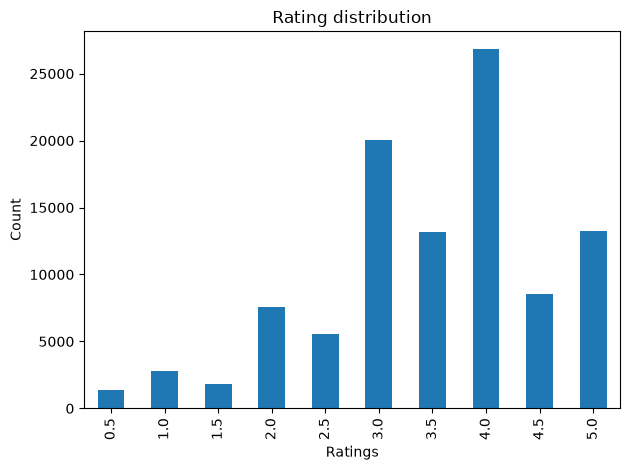

In [17]:
ratings["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Rating distribution")
plt.xlabel("Ratings")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

`Rating distribution:` the most common rating is 4.0 (about 27,000), followed by 3.0 and then 3.5 and 5.0. 

Ratings skew positive, low ratings below 2.0 are a small minority, and whole-star ratings are used more than half-stars. With a mean of 3.5, `a model that guessed “about 3.5” for everything would look decent on error metrics while being useless for ranking`. 

## 5: The Long Tail of Popularity

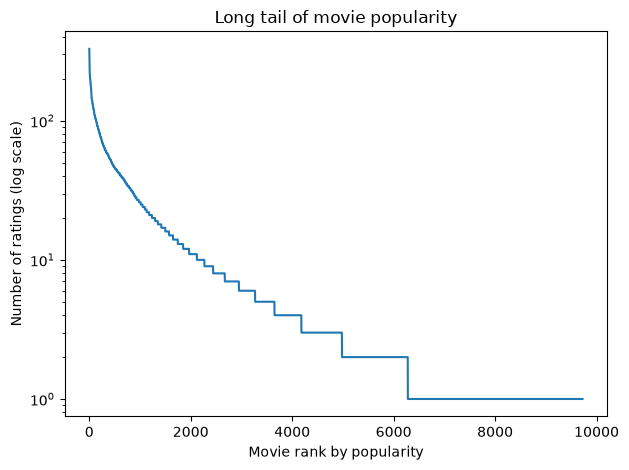

Movies with fewer than 5 ratings: 6074
Share of ratings going to the top 10% of movies: 60.0%


In [18]:
movie_counts = ratings.groupby("movieId").size().sort_values(ascending=False)

plt.plot(movie_counts.values)
plt.yscale("log")
plt.xlabel("Movie rank by popularity")
plt.ylabel("Number of ratings (log scale)")
plt.title("Long tail of movie popularity")
plt.tight_layout()
plt.show()

print("Movies with fewer than 5 ratings:", (movie_counts < 5).sum())
top10 = movie_counts.head(int(0.1 * len(movie_counts))).sum() / n_ratings
print(f"Share of ratings going to the top 10% of movies: {top10:.1%}")

`Long tail`: 6,074 of 9,724 movies (62%) have fewer than 5 ratings, and the top 10% of movies receive 60% of all ratings. 

For a recommender, this means two things:

- A simple “most popular” baseline will be strong, so our models must beat it to be worth building.

Most movies have too little data to learn from, so we’ll filter them for training and track coverage, which is how much of the catalogue we ever recommend.

- User activity: the minimum is 20 ratings (MovieLens guarantees this), the median is 70.5, the mean is 165 and the maximum is 2,698. 

A mean far above the median means the distribution is right-skewed: a few heavy users contribute a large share of the data. When we evaluate, we’ll average metrics per user so those heavy users don’t dominate the score

`User activity`: the minimum is 20 ratings (MovieLens guarantees this), the median is 70.5, the mean is 165 and the maximum is 2,698. 

A mean far above the median means the `distribution is right-skewed`: a few heavy users contribute a large share of the data. When we evaluate, `we’ll average metrics per user so those heavy users don’t dominate the score.`

### Findings: long tail of popularity

The top 10% of movies receive 60% of all ratings, and 6,074 of 9,724 movies (62%) have fewer than 5 ratings. Attention is heavily concentrated on a few popular titles.

This has two consequences. A "most popular" recommender will be a strong baseline that any real model has to beat, and most movies have too little data to learn from, so we filter them out for training and track catalogue coverage to make sure the model doesn't only recommend blockbusters.

## 6: User  activity and Time Range

In [19]:
user_counts = ratings.groupby("userId").size()
print(user_counts.describe())

ratings["date"] = pd.to_datetime(ratings["timestamp"], unit="s")
print("Date range:", ratings["date"].min(), "to", ratings["date"].max())

count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
dtype: float64
Date range: 1996-03-29 18:36:55 to 2018-09-24 14:27:30
